# 🛒 Sales Analysis Dashboard — Superstore

Hi, I am **Md Emon Rana**, CSE student at Southeast University.
This notebook does the same work as `analysis.py`, step by step, in easy words.

**Question:** which products make money, and where does discount eat the profit?
**Data:** Sample Superstore, 9,994 order lines, 2015–2018 (Tableau sample data, public mirror).


## Step 1 — Load the data
First I load the CSV and look at the first rows, so I know what I have.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')

df = pd.read_csv('data/superstore.csv', encoding='latin-1')
print(df.shape)   # (9994, 21) — 9,994 order lines, 21 columns
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## Step 2 — Clean it
Dates become real dates. Only 11 Postal Code values are missing — I leave them blank, I do not fill in a made-up code.

In [2]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)
print('Missing values:') 
print(df.isna().sum()[df.isna().sum() > 0])
print('Date range:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())
df.to_csv('data/superstore_clean.csv', index=False)

Missing values:
Postal Code    11
dtype: int64
Date range: 2015-01-03 to 2018-12-30


## Step 3 — The big numbers (KPIs)
Total sales, total profit, and how many orders. Margin = profit / sales.

In [3]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
print(f"Total sales: ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}  (margin {total_profit/total_sales*100:.2f}%)")
print(f"Orders: {df['Order ID'].nunique():,}, order lines: {len(df):,}")

Total sales: $2,297,201
Total profit: $286,397  (margin 12.47%)
Orders: 5,009, order lines: 9,994


## Step 4 — Sales by category
Technology sells most — but does it earn most too?

In [4]:
by_cat = df.groupby('Category').agg(sales=('Sales','sum'), profit=('Profit','sum')).sort_values('sales', ascending=False)
by_cat

,sales,profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


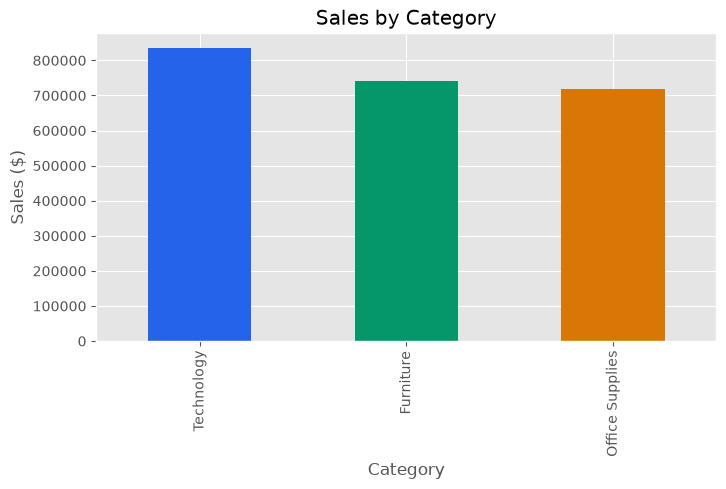

In [5]:
by_cat['sales'].plot(kind='bar', color=['#2563eb','#059669','#d97706'], figsize=(8,4))
plt.title('Sales by Category'); plt.ylabel('Sales ($)'); plt.show()

## Step 5 — Profit by region
West looks best. Central sells a lot but keeps little profit.

In [6]:
by_region = df.groupby('Region').agg(sales=('Sales','sum'), profit=('Profit','sum')).sort_values('sales', ascending=False)
by_region

,sales,profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


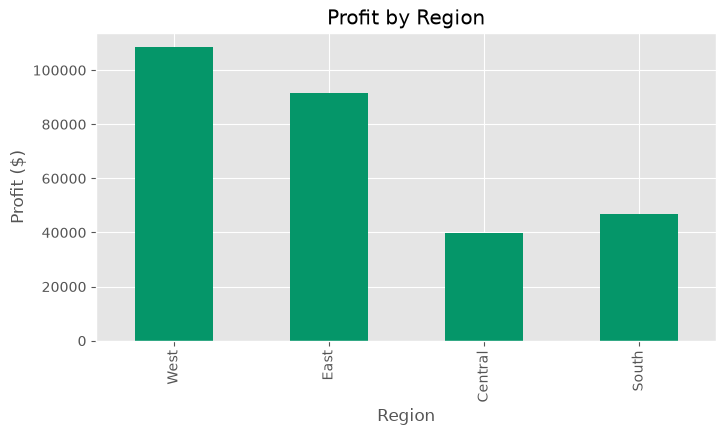

In [7]:
by_region['profit'].plot(kind='bar', color='#059669', figsize=(8,4))
plt.title('Profit by Region'); plt.ylabel('Profit ($)'); plt.show()

## Step 6 — Monthly trend
Sales go up in Sep–Dec every year — holiday season.

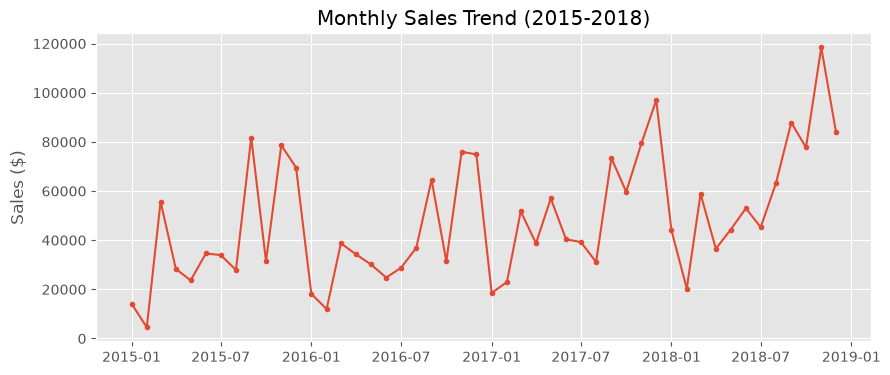

In [8]:
by_month = df.groupby('Month').agg(sales=('Sales','sum')).reset_index()
plt.figure(figsize=(10,4))
plt.plot(pd.to_datetime(by_month['Month']), by_month['sales'], marker='o', ms=3)
plt.title('Monthly Sales Trend (2015-2018)'); plt.ylabel('Sales ($)'); plt.show()

## Step 7 — Discount vs profit — the main finding
No discount = big profit. Discount over 20% = loss. This is the clearest chart in the project.

In [9]:
bins = pd.cut(df['Discount'], bins=[-0.01, 0, 0.2, 0.4, 0.8], labels=['0%','1-20%','21-40%','41-80%'])
disc = df.groupby(bins, observed=True).agg(sales=('Sales','sum'), profit=('Profit','sum'))
disc

,sales,profit
Discount,,
0%,1.087908e+06,320987.6032
1-20%,8.465222e+05,100785.4745
21-40%,2.341379e+05,-35817.4655
41-80%,1.286323e+05,-99558.5905


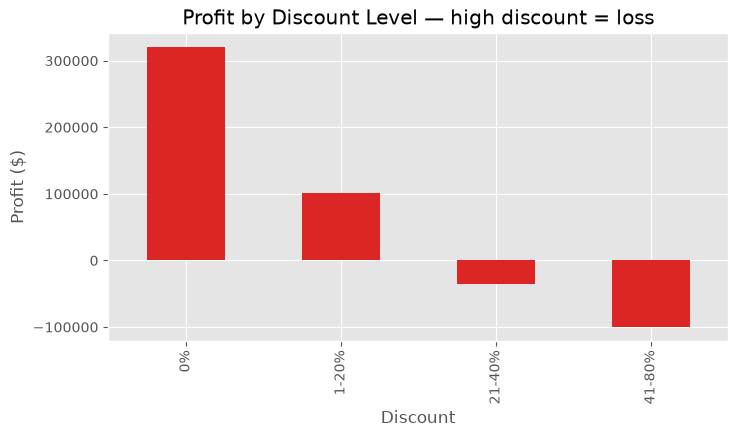

In [10]:
disc['profit'].plot(kind='bar', color='#dc2626', figsize=(8,4))
plt.title('Profit by Discount Level — high discount = loss'); plt.ylabel('Profit ($)'); plt.show()

## Step 8 — Top 10 products
The Canon copier is number 1 by sales. Tables lose money — check the report for the full list.

In [11]:
top10 = df.groupby('Product Name').agg(sales=('Sales','sum'), profit=('Profit','sum')).sort_values('sales', ascending=False).head(10)
top10

,sales,profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03


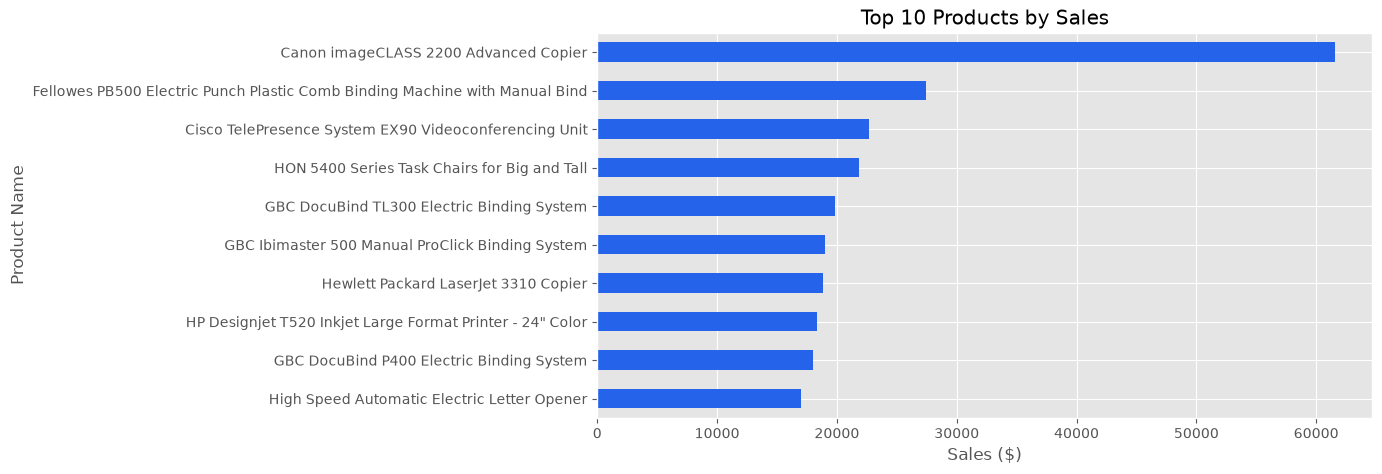

In [12]:
top10['sales'].sort_values().plot(kind='barh', color='#2563eb', figsize=(10,5))
plt.title('Top 10 Products by Sales'); plt.xlabel('Sales ($)'); plt.show()

## What I learned
- Technology: $836k sales, $145k profit — push this.
- Furniture: $742k sales, only $18k profit — Tables lose $17,725, fix the price.
- Discount over 20% loses money (41–80% discount lost $99,559) — cap discounts at 20%.
- West is the best region, Central is weakest on profit.

**Honest note:** this is Tableau's *sample* dataset, not a real shop's live sales, so it shows the method, not a real market. See `REPORT.md` for the full write-up, and `dashboard.html` for the interactive version.
